# Variational Autoencoders: 2D Data and Conditional MNIST

This notebook implements VAEs in PyTorch. It begins with a two-dimensional **two-moons** dataset, then trains a **conditional VAE (CVAE)** on MNIST handwritten digits. We compare **latent-space sizes** and **network architectures**, measure reconstruction and KL losses, and inspect **new samples drawn from the latent prior** (not just reconstructions).

Run cells from top to bottom in **VS Code** using the `vae-assignment` Conda kernel. Set `QUICK_RUN = True` for a short check; switch to `False` for your report experiments.

In [3]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset, random_split

SEED = 42
QUICK_RUN = True  # Change to False for the final experiments
OUTPUT_DIRECTORY = Path("vae_outputs")
OUTPUT_DIRECTORY.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE} | Quick run: {QUICK_RUN}")

Device: cpu | Quick run: True


## Part 1 — Two moons (2D)

We can see both the input distribution and the model's generated samples in a scatter plot. The moons are created with NumPy (no scikit-learn dependency). All normalization statistics come from the **training split**.

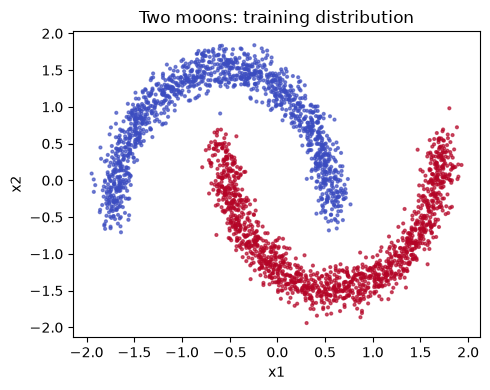

In [4]:
def generate_two_moons(samples_per_moon=2000, noise=0.07, seed=42):
    generator = np.random.default_rng(seed)
    first_angles = generator.uniform(0.0, np.pi, samples_per_moon)
    second_angles = generator.uniform(0.0, np.pi, samples_per_moon)
    first_moon = np.column_stack([np.cos(first_angles), np.sin(first_angles)])
    second_moon = np.column_stack([1.0 - np.cos(second_angles), 0.5 - np.sin(second_angles)])
    points = np.concatenate([first_moon, second_moon], axis=0)
    labels = np.concatenate([np.zeros(samples_per_moon), np.ones(samples_per_moon)]).astype(int)
    points += generator.normal(0.0, noise, size=points.shape)
    shuffled_indices = generator.permutation(len(points))
    return points[shuffled_indices].astype(np.float32), labels[shuffled_indices]

moon_points, moon_labels = generate_two_moons(seed=SEED)
random_indices = np.random.default_rng(SEED + 1).permutation(len(moon_points))
train_end = int(0.7 * len(random_indices))
validation_end = int(0.85 * len(random_indices))
train_indices = random_indices[:train_end]
validation_indices = random_indices[train_end:validation_end]
test_indices = random_indices[validation_end:]

training_mean = moon_points[train_indices].mean(axis=0)
training_std = moon_points[train_indices].std(axis=0)
standardized_points = (moon_points - training_mean) / training_std

def make_moon_loader(indices, shuffle=False):
    dataset = TensorDataset(torch.tensor(standardized_points[indices], dtype=torch.float32))
    return DataLoader(dataset, batch_size=128, shuffle=shuffle, num_workers=0)

moon_train_loader = make_moon_loader(train_indices, shuffle=True)
moon_validation_loader = make_moon_loader(validation_indices)
moon_test_loader = make_moon_loader(test_indices)

plt.figure(figsize=(5, 4))
plt.scatter(standardized_points[train_indices, 0], standardized_points[train_indices, 1],
            c=moon_labels[train_indices], s=4, cmap="coolwarm", alpha=0.65)
plt.title("Two moons: training distribution")
plt.xlabel("x1"); plt.ylabel("x2")
plt.tight_layout()
plt.show()

### VAE and training functions

The encoder outputs a mean and log variance for a Gaussian latent distribution. We sample via the **reparameterization trick**, then decode. The training objective is mean reconstruction error plus `beta × KL divergence`; reported reconstruction and KL components remain separate.

In [5]:
def build_mlp(input_features, hidden_layers, output_features):
    layers = []
    previous_features = input_features
    for hidden_features in hidden_layers:
        layers.extend([nn.Linear(previous_features, hidden_features), nn.ReLU()])
        previous_features = hidden_features
    layers.append(nn.Linear(previous_features, output_features))
    return nn.Sequential(*layers)


class VariationalAutoencoder(nn.Module):
    def __init__(self, input_features, latent_dimensions, hidden_layers=(64, 64), num_classes=None):
        super().__init__()
        self.input_features = input_features
        self.latent_dimensions = latent_dimensions
        self.num_classes = num_classes
        conditional_features = num_classes or 0
        self.encoder = build_mlp(input_features + conditional_features, hidden_layers,
                                 2 * latent_dimensions)
        self.decoder = build_mlp(latent_dimensions + conditional_features,
                                 tuple(reversed(hidden_layers)), input_features)

    def append_condition(self, features, labels):
        if self.num_classes is None:
            return features
        if labels is None:
            raise ValueError("Conditional VAE requires class labels")
        one_hot_labels = torch.nn.functional.one_hot(labels.long(), self.num_classes).float()
        return torch.cat((features, one_hot_labels), dim=1)

    def forward(self, features, labels=None):
        encoder_output = self.encoder(self.append_condition(features, labels))
        latent_mean, latent_log_variance = encoder_output.chunk(2, dim=1)
        latent_std = torch.exp(0.5 * latent_log_variance)
        latent_sample = latent_mean + torch.randn_like(latent_std) * latent_std
        reconstruction = self.decoder(self.append_condition(latent_sample, labels))
        return reconstruction, latent_mean, latent_log_variance

    @torch.no_grad()
    def generate(self, sample_count, labels=None):
        self.eval()
        latent_samples = torch.randn(sample_count, self.latent_dimensions, device=DEVICE)
        return self.decoder(self.append_condition(latent_samples, labels))


def vae_loss(reconstruction, target, latent_mean, latent_log_variance,
             beta=1.0, binary_images=False):
    if binary_images:
        reconstruction_loss = torch.nn.functional.binary_cross_entropy_with_logits(
            reconstruction, target, reduction="sum") / target.shape[0]
    else:
        reconstruction_loss = torch.nn.functional.mse_loss(
            reconstruction, target, reduction="sum") / target.shape[0]
    kl_divergence = -0.5 * torch.sum(
        1.0 + latent_log_variance - latent_mean.pow(2) - latent_log_variance.exp()
    ) / target.shape[0]
    return reconstruction_loss + beta * kl_divergence, reconstruction_loss, kl_divergence


def evaluate_model(model, data_loader, beta=1.0, binary_images=False, optimizer=None):
    training = optimizer is not None
    model.train(training)
    totals = np.zeros(3, dtype=float)
    observed_examples = 0
    for batch in data_loader:
        features = batch[0].to(DEVICE)
        labels = batch[1].to(DEVICE) if len(batch) > 1 else None
        flattened_features = features.reshape(features.shape[0], -1)
        with torch.set_grad_enabled(training):
            reconstruction, latent_mean, latent_log_variance = model(flattened_features, labels)
            total_loss, reconstruction_loss, kl_loss = vae_loss(
                reconstruction, flattened_features, latent_mean, latent_log_variance,
                beta=beta, binary_images=binary_images)
            if training:
                optimizer.zero_grad()
                total_loss.backward()
                optimizer.step()
        batch_size = features.shape[0]
        totals += np.array([total_loss.item(), reconstruction_loss.item(), kl_loss.item()]) * batch_size
        observed_examples += batch_size
    return totals / observed_examples


def fit_model(model, training_loader, validation_loader, epochs, learning_rate=1e-3,
              beta=1.0, binary_images=False):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    for epoch in range(epochs):
        training_metrics = evaluate_model(model, training_loader, beta, binary_images, optimizer)
        validation_metrics = evaluate_model(model, validation_loader, beta, binary_images)
        history.append([*training_metrics, *validation_metrics])
    return np.asarray(history)


def print_metrics(name, model, history, test_loader, binary_images=False):
    test_metrics = evaluate_model(model, test_loader, binary_images=binary_images)
    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    print(f"{name:18} parameters={parameter_count:>7,} "
          f"val_total={history[-1, 3]:.3f} test_recon={test_metrics[1]:.3f} "
          f"test_KL={test_metrics[2]:.3f}")
    return test_metrics

### Experiment 1: latent dimensions

Keep the architecture fixed; compare latent dimensions **1, 2, 4, and 8**. Look at generated *new* points and consider whether each model captures both curved moons or fills in the space between them.

Moon latent 1      parameters=  8,900 val_total=1.568 test_recon=1.039 test_KL=0.514
Moon latent 2      parameters=  9,094 val_total=1.547 test_recon=1.053 test_KL=0.498
Moon latent 4      parameters=  9,482 val_total=1.630 test_recon=1.151 test_KL=0.517
Moon latent 8      parameters= 10,258 val_total=1.641 test_recon=1.094 test_KL=0.531


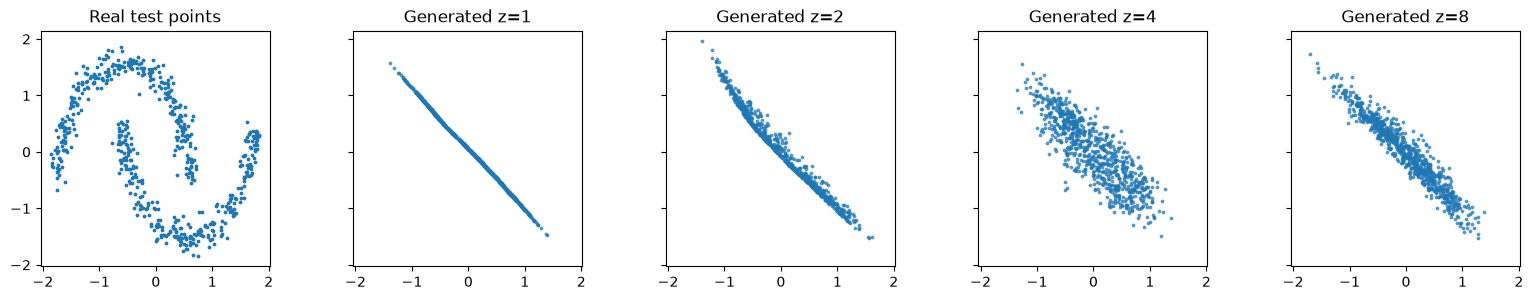

In [6]:
MOON_EPOCHS = 5 if QUICK_RUN else 40
moon_latent_sizes = [1, 2, 4, 8]
moon_models = {}
moon_histories = {}

for latent_dimensions in moon_latent_sizes:
    torch.manual_seed(SEED)
    model = VariationalAutoencoder(2, latent_dimensions, hidden_layers=(64, 64)).to(DEVICE)
    history = fit_model(model, moon_train_loader, moon_validation_loader, MOON_EPOCHS)
    moon_models[latent_dimensions] = model
    moon_histories[latent_dimensions] = history
    print_metrics(f"Moon latent {latent_dimensions}", model, history, moon_test_loader)

fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharex=True, sharey=True)
axes[0].scatter(standardized_points[test_indices, 0], standardized_points[test_indices, 1], s=3)
axes[0].set_title("Real test points")
for axis, latent_dimensions in zip(axes[1:], moon_latent_sizes):
    samples = moon_models[latent_dimensions].generate(800).cpu().numpy()
    axis.scatter(samples[:, 0], samples[:, 1], s=3, alpha=0.65)
    axis.set_title(f"Generated z={latent_dimensions}")
for axis in axes:
    axis.set_aspect("equal", adjustable="box")
fig.tight_layout()
fig.savefig(OUTPUT_DIRECTORY / "moons_latent_samples.png", dpi=150)
plt.show()

### Experiment 2: network width/depth

Hold latent dimension at **2** and change hidden-layer structure. Compare both **validation loss** and **generated samples**. Parameter count is shown so the compute-capacity tradeoff is visible.

shallow-32         parameters=    390 val_total=1.747 test_recon=1.247 test_KL=0.415
medium-64x2        parameters=  9,094 val_total=1.547 test_recon=1.053 test_KL=0.498
deep-128x3         parameters= 67,590 val_total=1.583 test_recon=0.920 test_KL=0.652


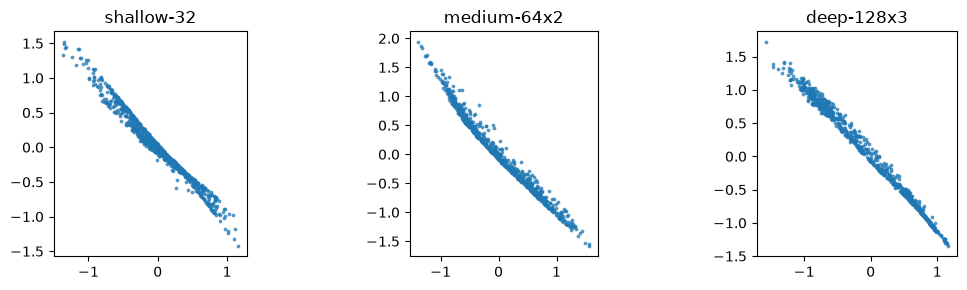

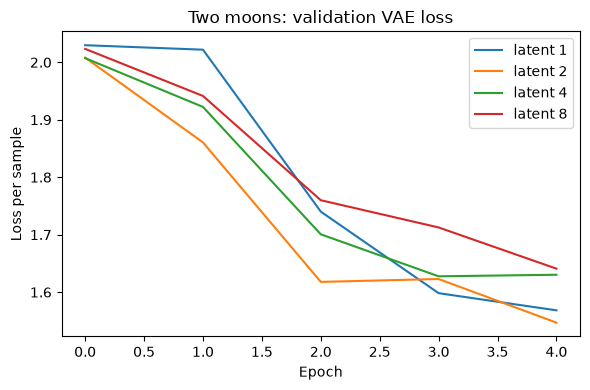

In [7]:
moon_architectures = {"shallow-32": (32,), "medium-64x2": (64, 64), "deep-128x3": (128, 128, 128)}
moon_architecture_results = {}
fig, axes = plt.subplots(1, len(moon_architectures), figsize=(11, 3))
for axis, (architecture_name, hidden_layers) in zip(axes, moon_architectures.items()):
    torch.manual_seed(SEED)
    model = VariationalAutoencoder(2, 2, hidden_layers=hidden_layers).to(DEVICE)
    history = fit_model(model, moon_train_loader, moon_validation_loader, MOON_EPOCHS)
    moon_architecture_results[architecture_name] = (model, history)
    print_metrics(architecture_name, model, history, moon_test_loader)
    samples = model.generate(800).cpu().numpy()
    axis.scatter(samples[:, 0], samples[:, 1], s=3, alpha=0.65)
    axis.set_title(architecture_name)
    axis.set_aspect("equal", adjustable="box")
fig.tight_layout()
fig.savefig(OUTPUT_DIRECTORY / "moons_architecture_samples.png", dpi=150)
plt.show()

plt.figure(figsize=(6, 4))
for latent_dimensions, history in moon_histories.items():
    plt.plot(history[:, 3], label=f"latent {latent_dimensions}")
plt.title("Two moons: validation VAE loss")
plt.xlabel("Epoch"); plt.ylabel("Loss per sample"); plt.legend()
plt.tight_layout(); plt.show()

**Two-moons discussion (replace with your observations after a full run):**

- Which latent dimension best represents both arcs? Does a larger latent space help beyond dimension 2?
- Are there unrealistic generated points between the arcs? Compare sample quality with held-out reconstruction loss and KL divergence.
- Which architecture appears to produce the cleanest samples? Does the increase in parameters justify the difference?

Do not claim improvements based only on one small `QUICK_RUN` test.

## Part 2 — Conditional VAE on MNIST

MNIST has **28 × 28 grayscale images** of digits 0–9. We condition **both encoder and decoder** on one-hot digit labels so we can request specific digits when sampling. The first dataset use downloads MNIST into `data/`; subsequent runs reuse it.

The decoder produces logits, trained with **binary cross-entropy with logits**, and we apply `sigmoid` only for displaying images.

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data\MNIST\raw\train-images-idx3-ubyte.gz to data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data\MNIST\raw\train-labels-idx1-ubyte.gz to data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data\MNIST\raw\t10k-images-idx3-ubyte.gz to data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data\MNIST\raw\t10k-labels-idx1-ubyte.gz to data\MNIST\raw



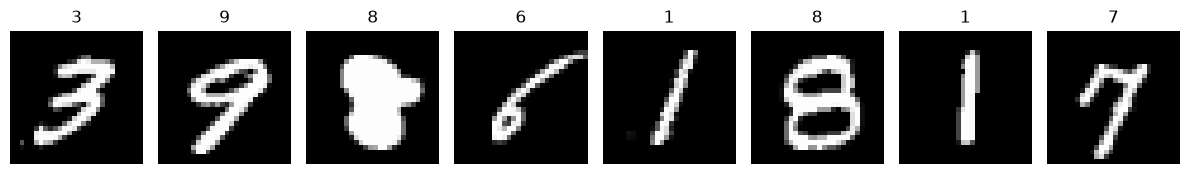

In [8]:
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

full_training_dataset = MNIST(root="data", train=True, download=True, transform=ToTensor())
full_test_dataset = MNIST(root="data", train=False, download=True, transform=ToTensor())

split_generator = torch.Generator().manual_seed(SEED)
training_dataset, validation_dataset = random_split(
    full_training_dataset, [50000, 10000], generator=split_generator)

# Limits make the notebook practical on a CPU. Increase for higher-quality final results.
TRAIN_LIMIT = 2000 if QUICK_RUN else 12000
VALIDATION_LIMIT = 500 if QUICK_RUN else 2000
TEST_LIMIT = 500 if QUICK_RUN else 2000

training_dataset = Subset(training_dataset, range(TRAIN_LIMIT))
validation_dataset = Subset(validation_dataset, range(VALIDATION_LIMIT))
test_dataset = Subset(full_test_dataset, range(TEST_LIMIT))

mnist_train_loader = DataLoader(training_dataset, batch_size=128, shuffle=True, num_workers=0)
mnist_validation_loader = DataLoader(validation_dataset, batch_size=256, num_workers=0)
mnist_test_loader = DataLoader(test_dataset, batch_size=256, num_workers=0)

example_images, example_labels = next(iter(mnist_train_loader))
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for image_index, axis in enumerate(axes):
    axis.imshow(example_images[image_index, 0], cmap="gray", vmin=0, vmax=1)
    axis.set_title(str(example_labels[image_index].item()))
    axis.axis("off")
plt.tight_layout(); plt.show()

### Experiment 3: MNIST latent dimensions

Compare **2, 8, 16, 32** with the same architecture, training set, and epochs. The image grid draws *new random latent vectors*, conditioned on the requested class label. It is not a reconstruction grid.

MNIST latent 2     parameters=473,108 val_total=215.941 test_recon=204.378 test_KL=2.896
MNIST latent 8     parameters=475,424 val_total=214.297 test_recon=205.898 test_KL=1.442
MNIST latent 16    parameters=478,512 val_total=214.023 test_recon=202.262 test_KL=2.673
MNIST latent 32    parameters=484,688 val_total=210.771 test_recon=201.206 test_KL=1.129


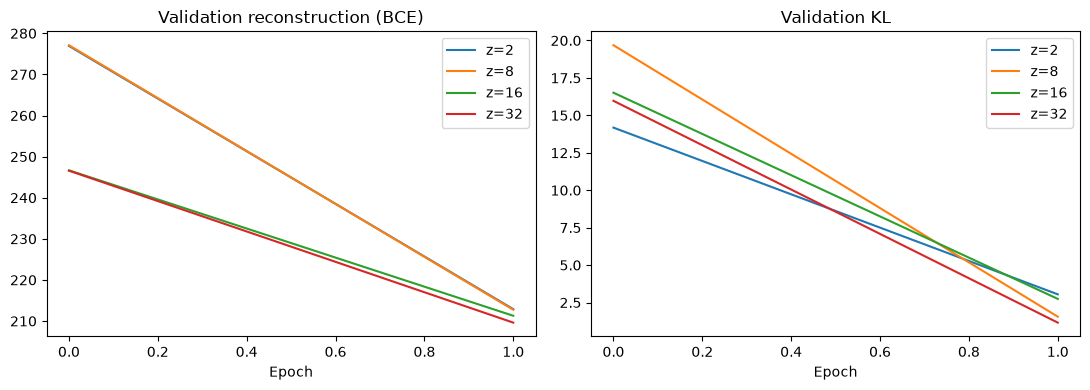

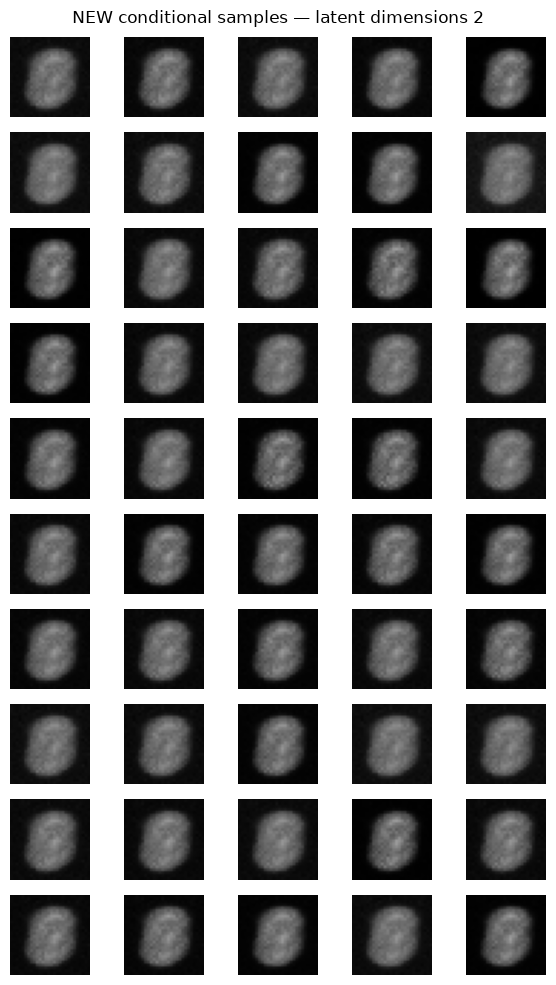

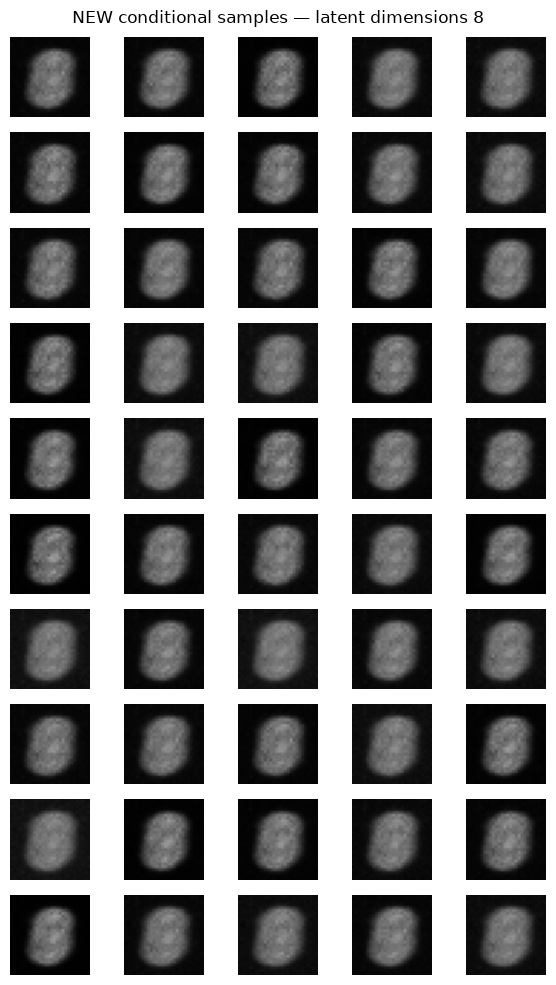

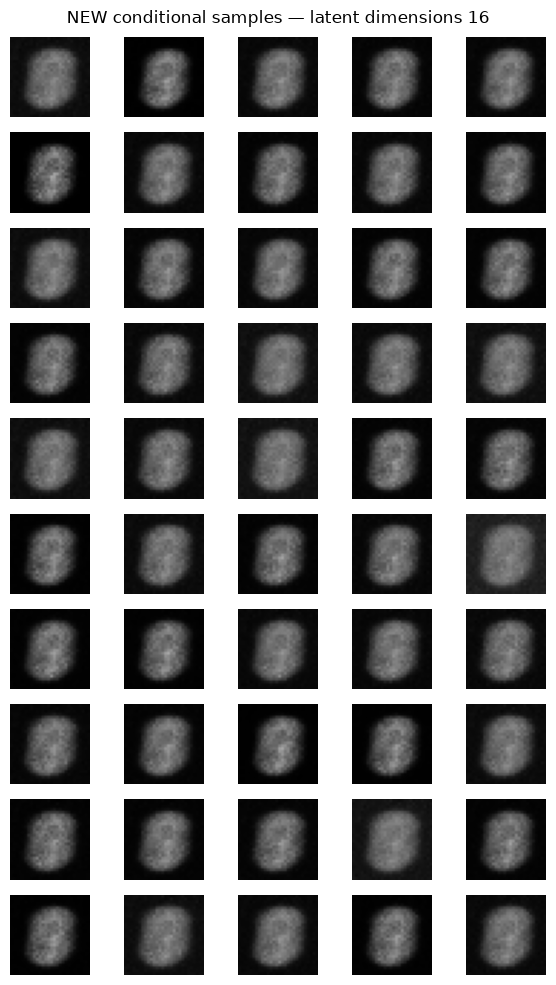

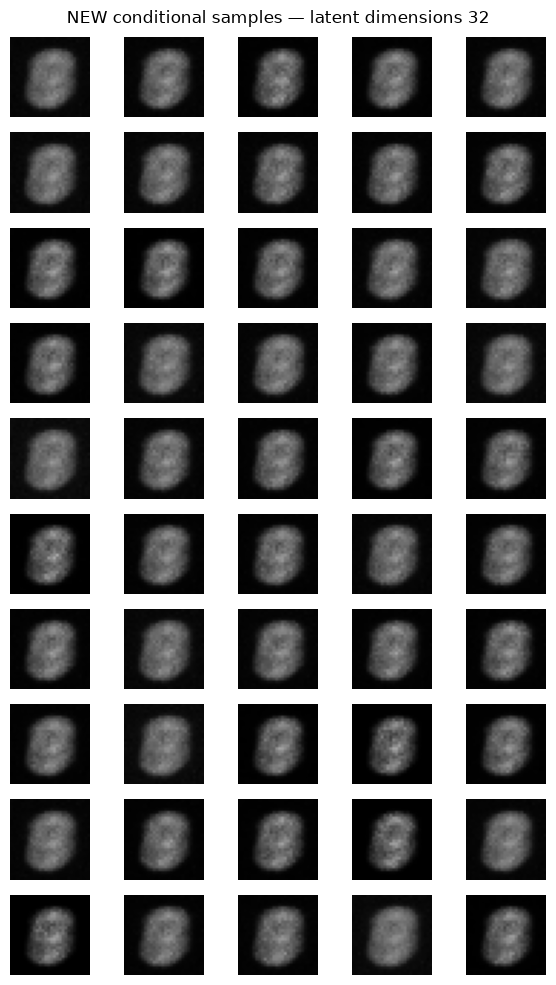

In [9]:
MNIST_EPOCHS = 2 if QUICK_RUN else 15
mnist_latent_sizes = [2, 8, 16, 32]
mnist_models = {}
mnist_histories = {}

@torch.no_grad()
def plot_conditional_samples(model, axis_grid, samples_per_class=5):
    labels = torch.arange(10, device=DEVICE).repeat_interleave(samples_per_class)
    samples = torch.sigmoid(model.generate(len(labels), labels)).cpu().reshape(-1, 28, 28)
    for digit in range(10):
        for sample_index in range(samples_per_class):
            axis = axis_grid[digit, sample_index]
            axis.imshow(samples[digit * samples_per_class + sample_index], cmap="gray", vmin=0, vmax=1)
            axis.axis("off")
            if sample_index == 0:
                axis.set_ylabel(str(digit), rotation=0, labelpad=10)

for latent_dimensions in mnist_latent_sizes:
    torch.manual_seed(SEED)
    model = VariationalAutoencoder(784, latent_dimensions, (256, 128), num_classes=10).to(DEVICE)
    history = fit_model(model, mnist_train_loader, mnist_validation_loader,
                        MNIST_EPOCHS, binary_images=True)
    mnist_models[latent_dimensions] = model
    mnist_histories[latent_dimensions] = history
    print_metrics(f"MNIST latent {latent_dimensions}", model, history,
                  mnist_test_loader, binary_images=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for latent_dimensions, history in mnist_histories.items():
    axes[0].plot(history[:, 4], label=f"z={latent_dimensions}")
    axes[1].plot(history[:, 5], label=f"z={latent_dimensions}")
axes[0].set_title("Validation reconstruction (BCE)")
axes[1].set_title("Validation KL")
for axis in axes:
    axis.set_xlabel("Epoch"); axis.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIRECTORY / "mnist_latent_curves.png", dpi=150)
plt.show()

for latent_dimensions, model in mnist_models.items():
    figure, grid = plt.subplots(10, 5, figsize=(6, 10))
    plot_conditional_samples(model, grid)
    figure.suptitle(f"NEW conditional samples — latent dimensions {latent_dimensions}")
    figure.tight_layout()
    figure.savefig(OUTPUT_DIRECTORY / f"mnist_generated_z{latent_dimensions}.png", dpi=150)
    plt.show()

### Experiment 4: conditional VAE architecture

Keep latent dimension **8** and test three different widths/depths. Evaluate on identical data, then generate digit samples for a visual comparison.

shallow-64         parameters=104,096 val_total=336.943 test_recon=292.008 test_KL=32.735


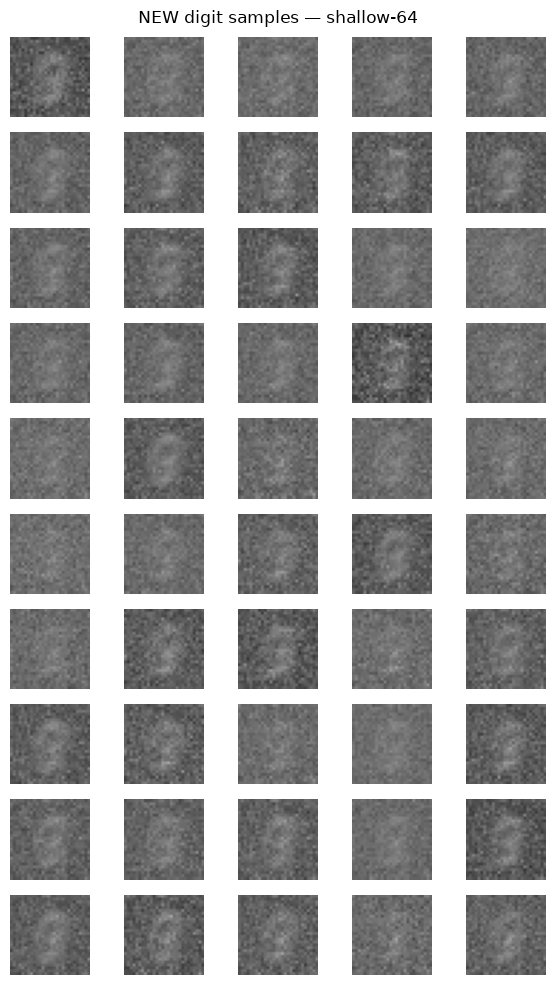

medium-256x128     parameters=475,424 val_total=214.297 test_recon=205.898 test_KL=1.442


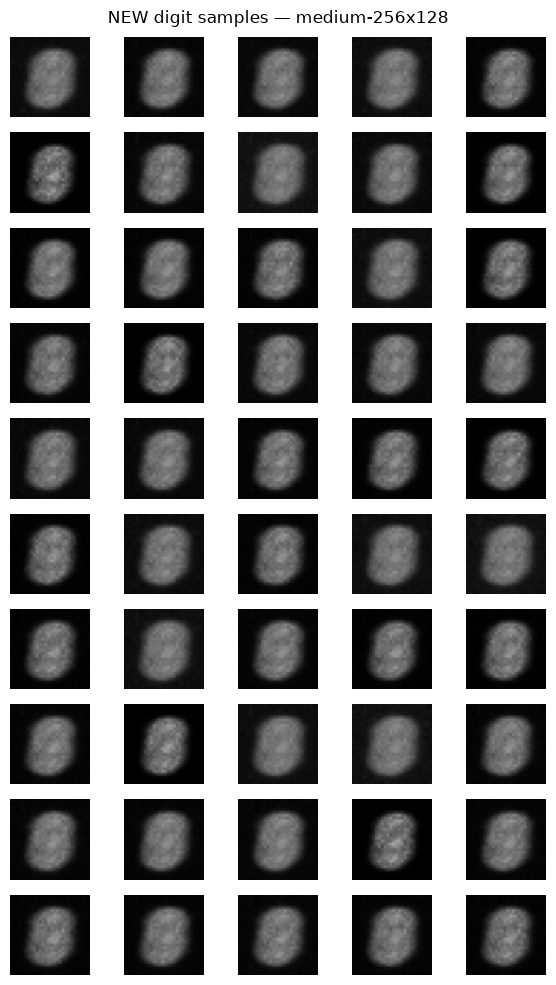

deep-256x128x64    parameters=489,760 val_total=214.184 test_recon=208.429 test_KL=0.779


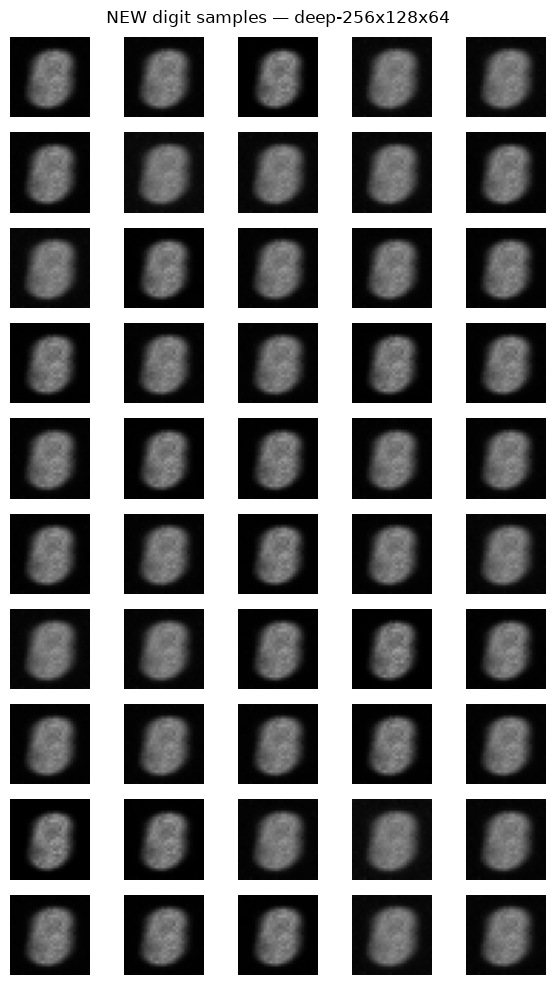

In [10]:
mnist_architectures = {
    "shallow-64": (64,),
    "medium-256x128": (256, 128),
    "deep-256x128x64": (256, 128, 64),
}
mnist_architecture_results = {}
for architecture_name, hidden_layers in mnist_architectures.items():
    torch.manual_seed(SEED)
    model = VariationalAutoencoder(784, 8, hidden_layers, num_classes=10).to(DEVICE)
    history = fit_model(model, mnist_train_loader, mnist_validation_loader,
                        MNIST_EPOCHS, binary_images=True)
    mnist_architecture_results[architecture_name] = (model, history)
    print_metrics(architecture_name, model, history, mnist_test_loader, binary_images=True)
    figure, grid = plt.subplots(10, 5, figsize=(6, 10))
    plot_conditional_samples(model, grid)
    figure.suptitle(f"NEW digit samples — {architecture_name}")
    figure.tight_layout()
    figure.savefig(OUTPUT_DIRECTORY / f"mnist_{architecture_name}.png", dpi=150)
    plt.show()

### Reconstructions versus newly generated images

Reconstructions use **held-out test images** passed through the encoder. New generations instead sample the latent prior, with only a digit label specified. Both are worth inspecting, but **generated samples are the key requirement** for this assignment.

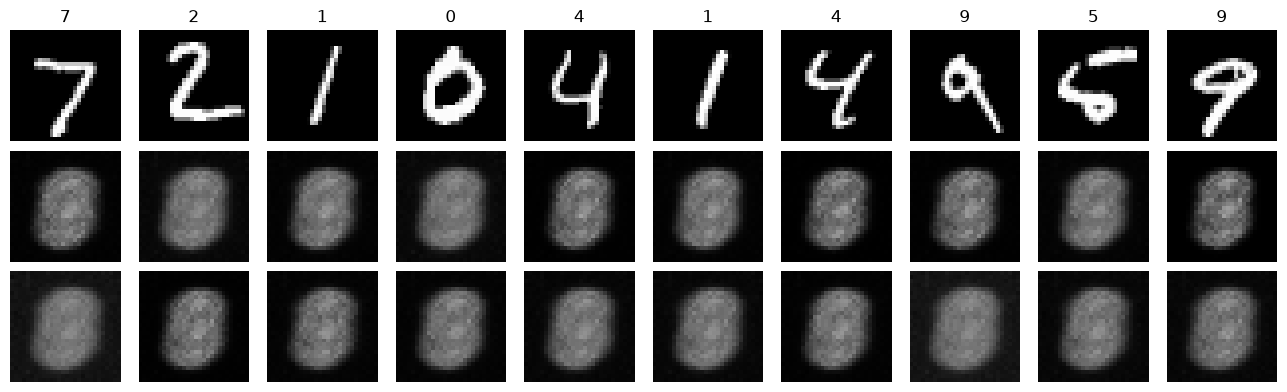

In [11]:
best_candidate = mnist_models[8]
best_candidate.eval()
real_images, real_labels = next(iter(mnist_test_loader))
with torch.no_grad():
    input_batch = real_images[:10].to(DEVICE).reshape(10, 784)
    label_batch = real_labels[:10].to(DEVICE)
    logits, _, _ = best_candidate(input_batch, label_batch)
    reconstructions = torch.sigmoid(logits).cpu().reshape(-1, 28, 28)
    new_samples = torch.sigmoid(best_candidate.generate(10, label_batch)).cpu().reshape(-1, 28, 28)

figure, grid = plt.subplots(3, 10, figsize=(13, 4))
for index in range(10):
    for row_index, image in enumerate((real_images[index, 0], reconstructions[index], new_samples[index])):
        grid[row_index, index].imshow(image, cmap="gray", vmin=0, vmax=1)
        grid[row_index, index].axis("off")
        if row_index == 0:
            grid[row_index, index].set_title(str(real_labels[index].item()))
for row_index, label in enumerate(("Real", "Reconstructed", "New sample")):
    grid[row_index, 0].set_ylabel(label, rotation=90)
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / "mnist_real_vs_reconstructed_vs_new.png", dpi=150)
plt.show()

## Report discussion — complete after running `QUICK_RUN = False`

1. **Two moons:** Which latent sizes generated realistic arcs? What happened when latent size increased beyond the input dimension? Compare validation reconstruction and KL losses against actual sample distributions.
2. **Conditional MNIST:** Across latent dimensions 2, 8, 16, and 32, compare digit recognizability, stroke clarity, and **diversity within each label**. Were improvements consistent with validation reconstruction loss?
3. **Architectures:** Which shallow/medium/deep networks worked best? Explain the differences in sample quality, reconstruction, KL, and parameter count; avoid assuming that deeper is always better.
4. **Limitations:** The default full run uses a subset of MNIST and one random seed. Sample quality is assessed visually, so discuss ambiguity and any visible failures.
5. **Conclusions:** Identify the most convincing model and explain **why based on both metrics and new samples**. Only state findings that you actually observed.

**Method note:** Compare/select configurations using the validation set; reserve the held-out test set for final reporting. `QUICK_RUN=True` is a functionality check, not the basis for your conclusions.